# Gunpowder Flash (Mercenary)

Gunpowder Flash blinds the target with a burst of powder. For 30 s the target's **action
speed** (the speed row that gates attacks and other actions) drops by a number of points, and
the caster gets a 30 s haste. Enemies next to the caster that are attacking the caster are
slowed too. There is no resist roll and no cooldown.

| | |
|---|---|
| Class | Mercenary |
| Target | Selected enemy + caster's 4 cross neighbours **that are attacking the caster** |
| Cost | 7 mana (reduced by Concentration) |
| Cooldown | none; no exhaust |
| Landing roll | none: fails only on immortal targets or if power truncates to 0 |
| Duration | 30 s (slow on the target, haste on the caster) |
| Effect | target: `action_speed_calc −= slow`; caster: `action_speed_calc += 3`, `movement_speed_calc += 1` |
| Source | `server/src/driver/skill/mercenary.rs::skill_gunpowder_flash`, `gunpowder_flash_slow_points`; speed in `server/src/state/stats.rs::really_update_char` |

---

# Formula

The slow item stores $p' = \lfloor r\cdot\text{imm}(p, I)\rfloor$ (immunity $I$, caster race
multiplier $r$), and the target loses

$$
\text{slow} = \operatorname{clamp}\!\left(3 + \lfloor p'/40 \rfloor,\ 6,\ 20\right)
\ \text{action-speed points}
$$

Speed is a row index into the 20×40 `SPEEDTAB`; row $k$ allows $20 - k$ advances per 40 ticks.
A swing takes 8 advances, so

$$
\text{row} = \operatorname{clamp}(20 - \text{calc},\ 0,\ 19)
\qquad
\text{attacks/s} = \frac{36\,(20 - \text{row})}{40 \cdot 8}
$$

where `calc` starts from the base speed $\lfloor(\text{AGI}+\text{STR})/50\rfloor + \text{speed\_mod}
+ 14$ (normal mode), plus attack-speed talents. The caster's haste adds 3 to the action calc and
1 to the movement calc. The haste ignores power.

| Quantity | Breakpoint |
|---|---|
| Floor clamp | slow = 6 for every $p' < 160$ |
| Next step | slow = 7 at $p' \ge 160$, 8 at $p' \ge 200$ |
| Ceiling | slow = 20 at $p' \ge 680$ |
| Excess speed | base calc above 20 is wasted (row 0), but it absorbs the slow first |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
DURATION_S = 30
ENEMY_BASES = (14, 16, 18, 20, 22)

# Model

In [2]:
def flash_power(p, immun=0, race="Mercenary", moon=None):
    return mm.spell_power(p, immun, race, moon)


def slow_points(power):
    """`gunpowder_flash_slow_points(item.power)`."""
    return mm.clamp(3 + mm.idiv(power, 40), 6, 20)


def flash_slow(p, immun=0, race="Mercenary"):
    return slow_points(flash_power(p, immun, race))


def enemy_attacks_per_second(p, base, immun=0, race="Mercenary"):
    row = mm.action_speed_row(base, flash_slow=flash_slow(p, immun, race))
    return mm.attacks_per_second(row)

# Validation

- `gunpowder_flash_slow_points_are_clamped`: power 0 → 6, 400 → 13, 10,000 → 20.
- `gunpowder_flash` speed tests in `stats.rs`: a Flash item of power 80 makes the action row
  slower, and the Flash haste makes it faster.
- The cast costs 7 mana and both items last `TICKS*30`.
- `SPEEDTAB` row $k$ has exactly $20-k$ advances per 40 ticks.

In [3]:
assert slow_points(0) == 6 and slow_points(400) == 13 and slow_points(10_000) == 20
assert mm.action_speed_row(18, flash_slow=slow_points(80)) > mm.action_speed_row(18)
assert mm.action_speed_row(18, flash_haste=True) < mm.action_speed_row(18)
assert mm.spell_cost(7) == 7 and mm.TICKS * DURATION_S == 1080
assert list(mm.SPEEDTAB.sum(axis=1)) == list(range(20, 0, -1))

assert flash_slow(152) == 6 and flash_slow(153) == 7     # p' 159 -> 6, p' 160 -> 7 (Mercenary)
assert flash_power(10, immun=40, race="Templar") == 0    # immunity wall x 0.9 truncates to 0: cast fails
print("Gunpowder Flash model OK")

Gunpowder Flash model OK


# Plots

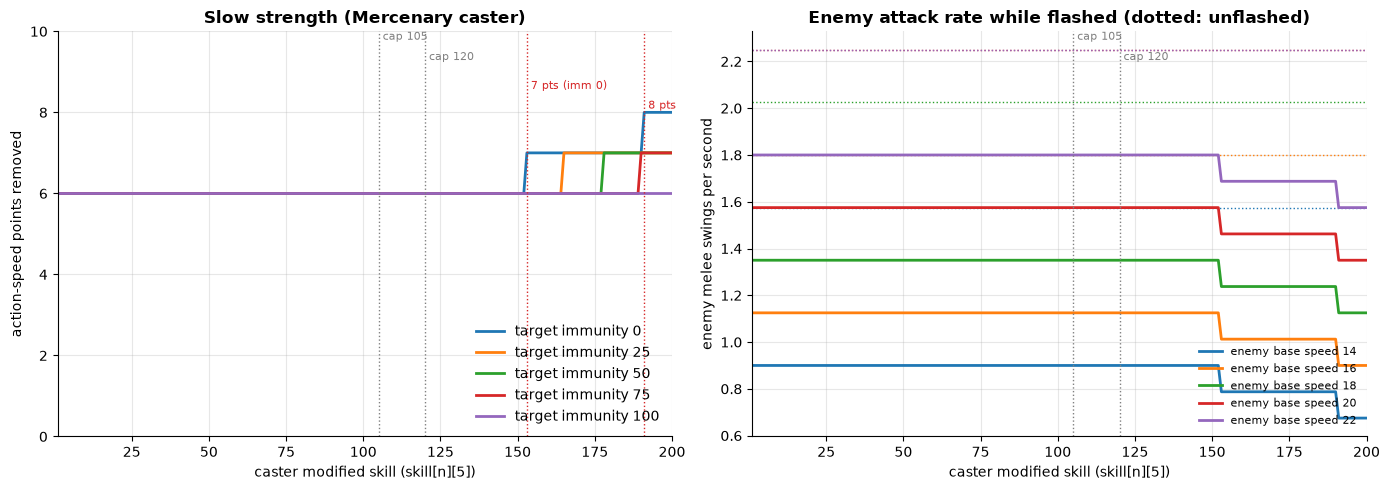

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for immun in mm.IMMUNITY_SWEEP:
    ax.plot(P, flash_slow(P, immun), label=f"target immunity {immun}")
mm.skill_axis(ax, "action-speed points removed", "Slow strength (Mercenary caster)")
ax.set_ylim(0, 10)
mm.mark_caps(ax, extra=[(153, "7 pts (imm 0)"), (191, "8 pts")])
ax.legend(loc="lower right")

ax = axes[1]
for base in ENEMY_BASES:
    line, = ax.plot(P, enemy_attacks_per_second(P, base), label=f"enemy base speed {base}")
    ax.axhline(mm.attacks_per_second(mm.action_speed_row(base)), color=line.get_color(), ls=":", lw=1)
mm.skill_axis(ax, "enemy melee swings per second", "Enemy attack rate while flashed (dotted: unflashed)")
mm.mark_caps(ax)
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()

The skill barely matters. The floor clamp of 6 holds until $p' = 160$, which a Mercenary reaches
at skill 153 against immunity 0. Within the plotted range the slow is 6, 7 or 8 points. What
matters is the enemy's speed. Each point of base speed above 20 is wasted while the enemy is
unaffected, but it soaks up a point of the slow.

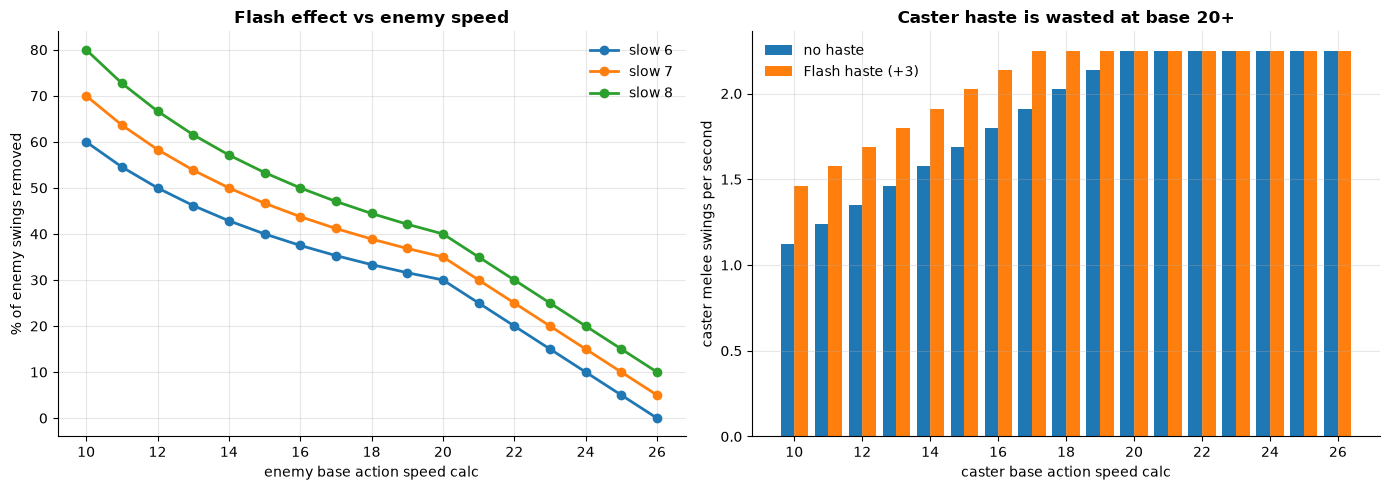

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Relative slow vs enemy base speed for the three slow values reachable below skill 200.
ax = axes[0]
bases = np.arange(10, 27)
for slow in (6, 7, 8):
    before = mm.attacks_per_second(mm.action_speed_row(bases))
    after = mm.attacks_per_second(mm.action_speed_row(bases, flash_slow=slow))
    ax.plot(bases, 100 * (1 - after / before), marker="o", label=f"slow {slow}")
ax.set_xlabel("enemy base action speed calc")
ax.set_ylabel("% of enemy swings removed")
ax.set_title("Flash effect vs enemy speed")
ax.legend()

# Caster haste vs caster base speed.
ax = axes[1]
before = mm.attacks_per_second(mm.action_speed_row(bases))
after = mm.attacks_per_second(mm.action_speed_row(bases, flash_haste=True))
ax.bar(bases - 0.2, before, width=0.4, label="no haste")
ax.bar(bases + 0.2, after, width=0.4, label="Flash haste (+3)")
ax.set_xticks(bases[::2])
ax.set_xlabel("caster base action speed calc")
ax.set_ylabel("caster melee swings per second")
ax.set_title("Caster haste is wasted at base 20+")
ax.legend()
plt.tight_layout()

# Observations

- **Effectively a flat ability.** Because of the 6-point floor, a skill-1 Flash and a skill-150
  Flash are identical. A Mercenary needs skill 153 (immunity 0) for a 7th point and 191 for an
  8th. Against immunity 100 the slow stays at 6 up to skill 200. Raising the skill past 1 buys
  nothing at the raise caps, so the clamp floor is the real balance knob.
- **Very strong for 7 mana.** A 6-point slow removes 33% of the swings of a base-18 enemy
  (2.03 → 1.35 per second) and 43% of a base-14 enemy's (1.58 → 0.90). It lasts 30 s, with no
  resist roll and no cooldown, and also hits every cross neighbour attacking the caster.
  Only immortality or Seeing Red stops it.
- **Fast enemies resist it.** A base-22 enemy, two points of "wasted" speed, loses only 20% of
  its swings. Excess speed above 20 acts as hidden Flash resistance.
- **The haste is often wasted.** The caster's +3 does nothing once their base action calc is 20
  or more, which a character reaches with AGI + STR ≥ 300 in normal mode. Below that it is worth
  up to +21% swings (base 14: 1.58 → 1.91 per second). The stored power is never read.
- **Rare failure through truncation.** `apply_gunpowder_flash` fails when $p' < 1$. That can
  only happen when the immunity wall reduces the power to 1 and the race multiplier is below 1,
  for example a Templar or Seyan'Du caster (×0.9/×0.95) or a new moon (−0.15).